In [2]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: C:\Users\GOHARY 10\anaconda3\envs\tf_env\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

print("scikit-learn:", sklearn.__version__)   # سجّل الرقم ده، هنحتاجه في requirements.txt
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

scikit-learn: 1.7.2


In [6]:
df = pd.read_csv("online_shoppers_intention.csv")
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [7]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nTarget balance:\n", df["Revenue"].value_counts(normalize=True))
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [11]:
print("Before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After :", df.shape)   

Before: (12330, 18)
After : (12205, 18)


In [12]:
X = df.drop(columns="Revenue")
y = df["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print("Train positive rate:", y_train.mean().round(3))
print("Test positive rate :", y_test.mean().round(3))

(9764, 17) (2441, 17)
Train positive rate: 0.156
Test positive rate : 0.156


In [13]:
# أعمدة أرقامها بس "أكواد" مش كميات، لازم تتعامل كفئات
code_cols = ["OperatingSystems", "Browser", "Region", "TrafficType"]
cat_cols  = ["Month", "VisitorType"] + code_cols
bool_cols = ["Weekend"]
num_cols  = [c for c in X_train.columns if c not in cat_cols + bool_cols]

print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical: ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], remainder="passthrough")   # Weekend بتعدي زي ما هي

baseline = Pipeline([("prep", preprocess),
                     ("model", DummyClassifier(strategy="most_frequent"))])

logreg = Pipeline([("prep", preprocess),
                   ("model", LogisticRegression(max_iter=1000))])

for name, pipe in [("Baseline", baseline), ("LogReg", logreg)]:
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="recall")
    print(f"{name:9s} recall (CV): {scores.mean():.3f}")

for name, pipe in [("Baseline", baseline), ("LogReg", logreg)]:
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    print(f"{name:9s} accuracy (CV): {scores.mean():.3f}")

Baseline  recall (CV): 0.000
LogReg    recall (CV): 0.373
Baseline  accuracy (CV): 0.844
LogReg    accuracy (CV): 0.882


In [15]:
train_df = X_train.copy()
train_df["Revenue"] = y_train

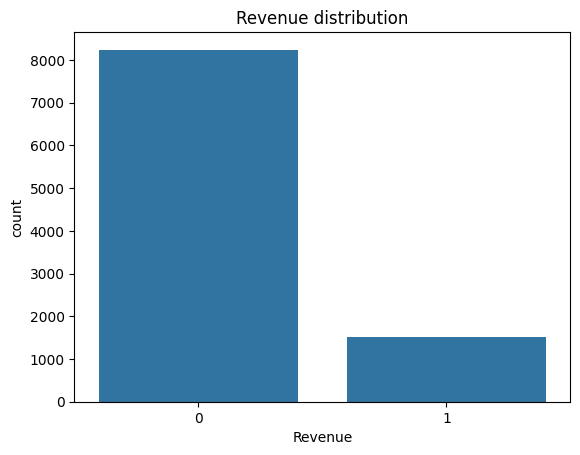

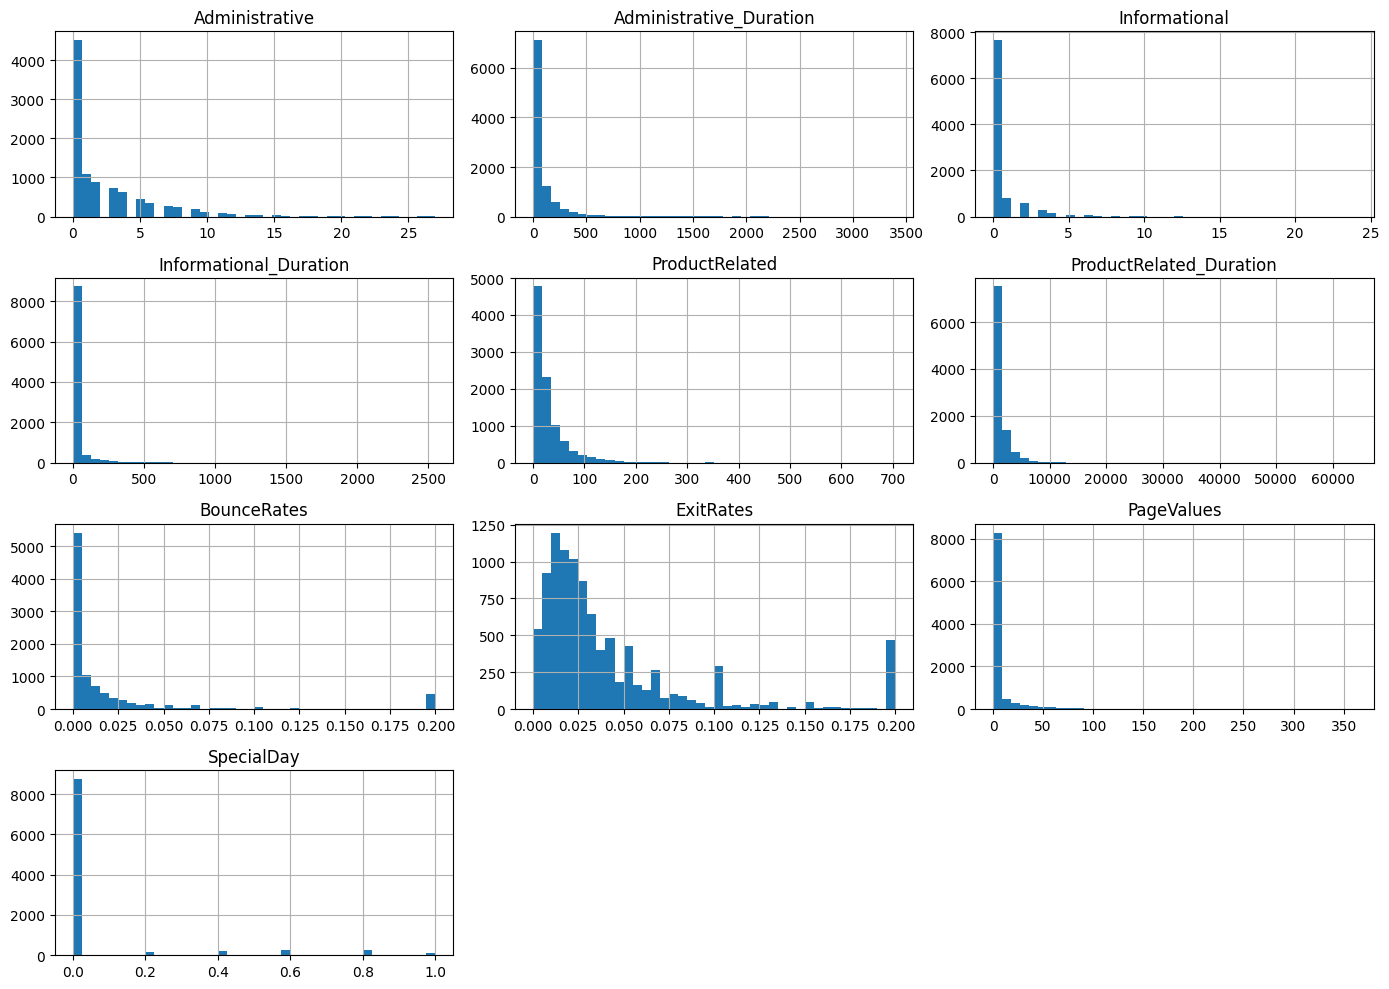

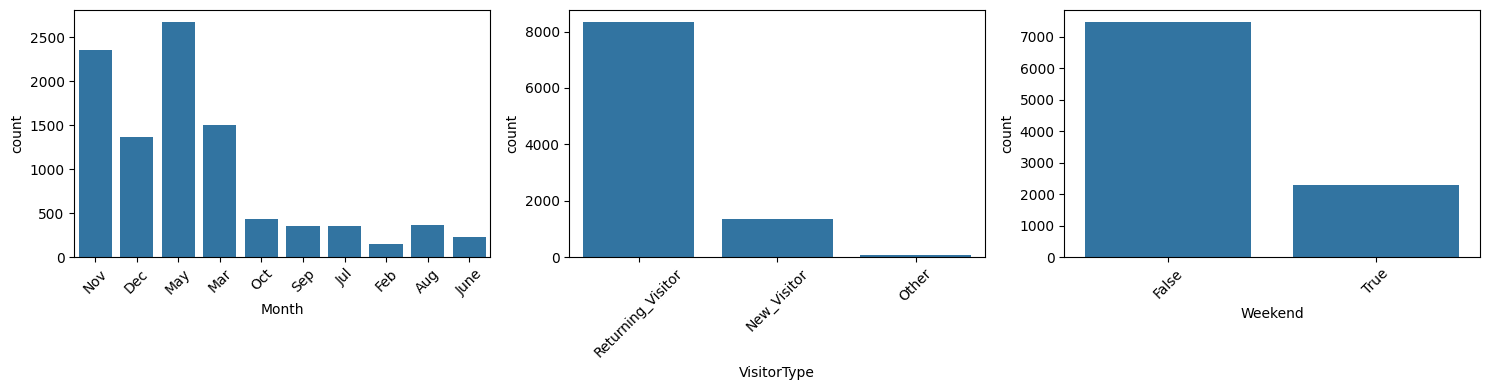

In [16]:
# 1) توزيع الهدف
sns.countplot(x="Revenue", data=train_df)
plt.title("Revenue distribution"); plt.show()

# 2) الأعمدة الرقمية
train_df[num_cols].hist(bins=40, figsize=(14, 10))
plt.tight_layout(); plt.show()

# 3) الأعمدة الفئوية
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Month", "VisitorType", "Weekend"]):
    sns.countplot(x=col, data=train_df, ax=ax)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

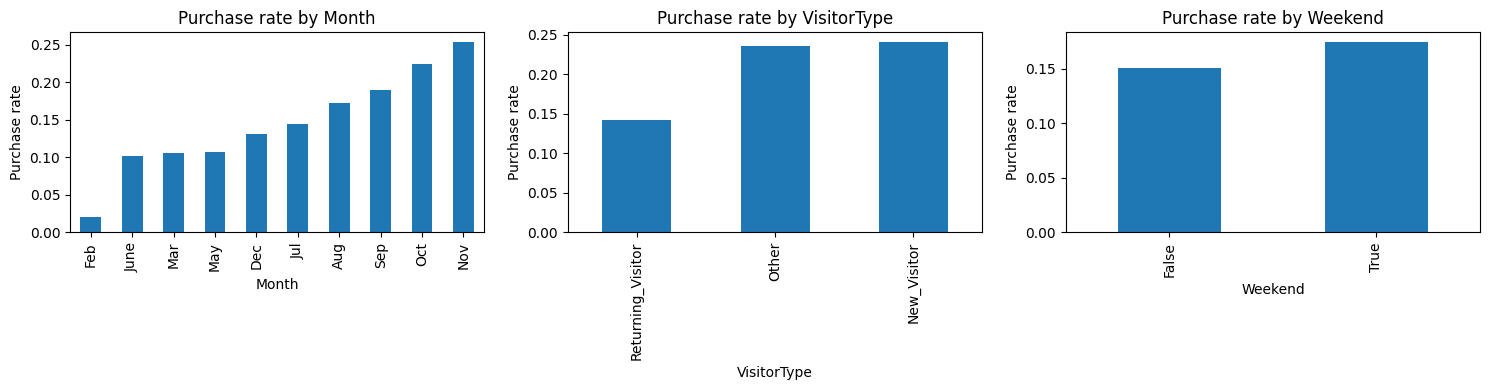

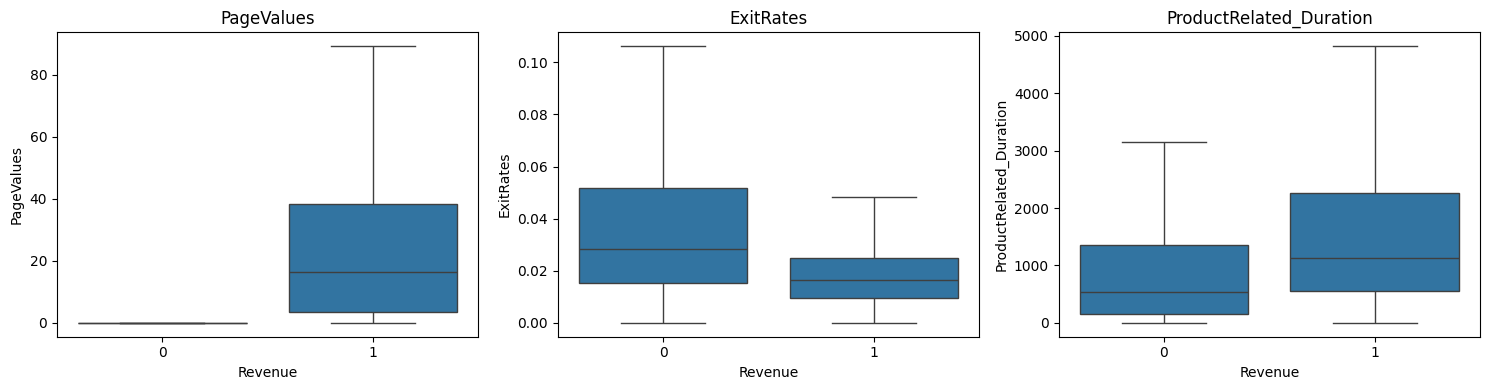

In [17]:
# نسبة الشراء لكل شهر / نوع زائر / ويك إند
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Month", "VisitorType", "Weekend"]):
    rate = train_df.groupby(col)["Revenue"].mean().sort_values()
    rate.plot(kind="bar", ax=ax)
    ax.set_title(f"Purchase rate by {col}")
    ax.set_ylabel("Purchase rate")
plt.tight_layout(); plt.show()

# الأعمدة الرقمية الأهم مقابل Revenue
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["PageValues", "ExitRates", "ProductRelated_Duration"]):
    sns.boxplot(x="Revenue", y=col, data=train_df, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout(); plt.show()

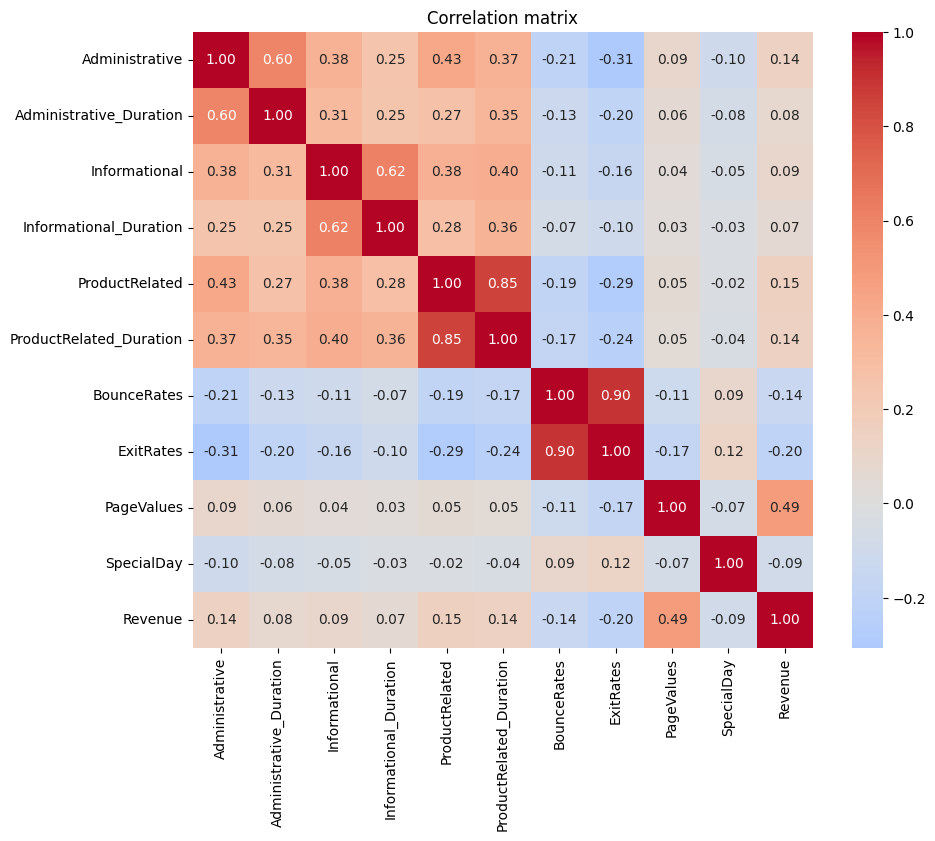

In [18]:
plt.figure(figsize=(10, 8))
corr = train_df[num_cols + ["Revenue"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

In [19]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "LogReg": LogisticRegression(max_iter=1000),
    "LogReg balanced": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "LogReg L1 balanced": LogisticRegression(penalty="l1", solver="liblinear",
                                             class_weight="balanced"),
}

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
rows = []
for name, m in models.items():
    res = cross_validate(make_pipe(m), X_train, y_train, cv=cv, scoring=metrics)
    rows.append({"model": name, **{k: res[f"test_{k}"].mean() for k in metrics}})

results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline,0.844,0.000,0.000,0.000,0.500
LogReg,0.882,0.742,0.372,0.495,0.889
LogReg balanced,0.847,0.508,0.752,0.606,0.899
LogReg L1 balanced,0.848,0.509,0.753,0.607,0.899


In [20]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__penalty": ["l1", "l2"],
}
pipe = make_pipe(LogisticRegression(solver="liblinear", class_weight="balanced"))

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))
best_model = grid.best_estimator_

Best params: {'model__C': 0.01, 'model__penalty': 'l1'}
Best CV ROC-AUC: 0.903


Chosen threshold: 0.528
Precision: 0.602 | Recall: 0.721


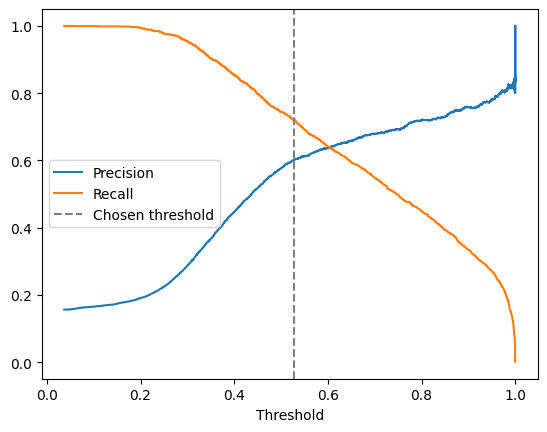

In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

proba_cv = cross_val_predict(best_model, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, proba_cv)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best_idx = np.argmax(f1[:-1])
best_thr = float(thr[best_idx])

print("Chosen threshold:", round(best_thr, 3))
print("Precision:", round(prec[best_idx], 3), "| Recall:", round(rec[best_idx], 3))

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(best_thr, color="gray", linestyle="--", label="Chosen threshold")
plt.xlabel("Threshold")
plt.legend()
plt.show()

              precision    recall  f1-score   support

      No buy       0.95      0.91      0.93      2059
         Buy       0.59      0.74      0.66       382

    accuracy                           0.88      2441
   macro avg       0.77      0.82      0.79      2441
weighted avg       0.89      0.88      0.88      2441

ROC-AUC: 0.913


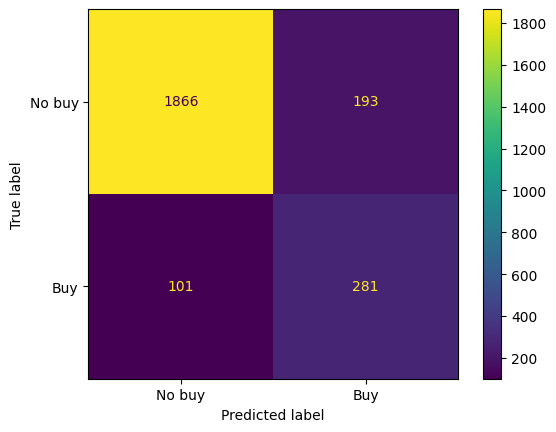

In [22]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, recall_score,
                             precision_score, accuracy_score, f1_score)

proba_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= best_thr).astype(int)

print(classification_report(y_test, pred_test, target_names=["No buy", "Buy"]))
print("ROC-AUC:", round(roc_auc_score(y_test, proba_test), 3))

ConfusionMatrixDisplay.from_predictions(y_test, pred_test,
                                        display_labels=["No buy", "Buy"])
plt.show()

In [23]:
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)

final = pd.DataFrame({
    "Baseline": [accuracy_score(y_test, base_pred), precision_score(y_test, base_pred, zero_division=0),
                 recall_score(y_test, base_pred), f1_score(y_test, base_pred), 0.5],
    "Best model": [accuracy_score(y_test, pred_test), precision_score(y_test, pred_test),
                   recall_score(y_test, pred_test), f1_score(y_test, pred_test),
                   roc_auc_score(y_test, proba_test)],
}, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).round(3)
final

,Baseline,Best model
Accuracy,0.844,0.880
Precision,0.000,0.593
Recall,0.000,0.736
F1,0.000,0.657
ROC-AUC,0.500,0.913


In [24]:
test_df = X_test.copy()
test_df["actual"] = y_test
test_df["pred"] = pred_test

print("Missed buyers (False Negatives):", ((test_df.actual == 1) & (test_df.pred == 0)).sum())
print("False alarms (False Positives):", ((test_df.actual == 0) & (test_df.pred == 1)).sum())

test_df.groupby(["actual", "pred"])[["PageValues", "ExitRates", "ProductRelated_Duration"]].mean().round(2)

Missed buyers (False Negatives): 101
False alarms (False Positives): 193


PageValues  ExitRates  ProductRelated_Duration
actual pred                                                
0      0           0.19       0.05                   841.26
       1          20.18       0.02                  3137.59
1      0           1.95       0.03                  1480.40
       1          35.98       0.02                  2201.50

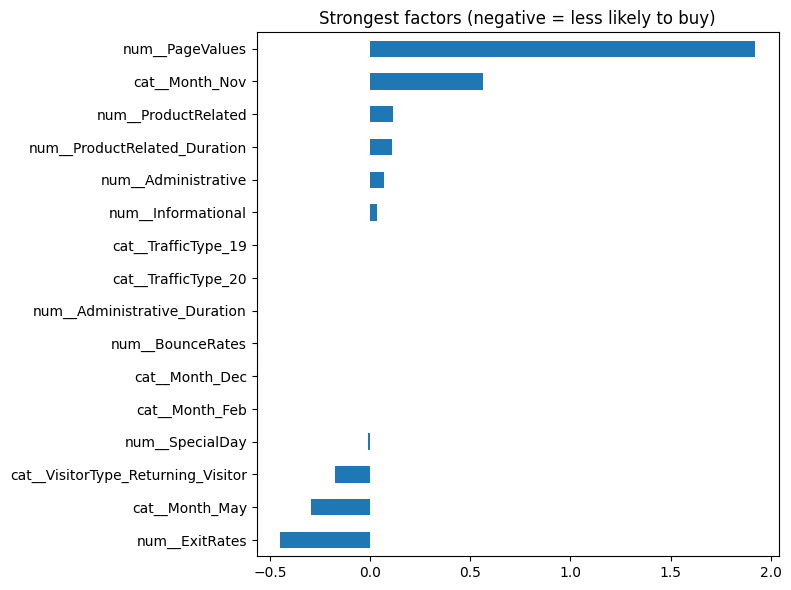

In [26]:
names = best_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(best_model.named_steps["model"].coef_[0], index=names).sort_values()

pd.concat([coefs.head(8), coefs.tail(8)]).plot(kind="barh", figsize=(8, 6))
plt.title("Strongest factors (negative = less likely to buy)")
plt.tight_layout()
plt.show()

In [27]:
import joblib

joblib.dump({"pipeline": best_model, "threshold": best_thr}, "model.joblib")
print("Saved. scikit-learn version:", sklearn.__version__)

Saved. scikit-learn version: 1.7.2
